In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder

# Task 1: Data Loading & Exploratory Data Analysis (EDA)


In [2]:
df = pd.read_csv('Dataset/Mall_Customers.csv')
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [4]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [5]:
df.shape

(200, 5)

In [6]:
df.isna().sum()

,0
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [7]:
df = df.drop(columns = ['CustomerID'])

In [8]:
df = df.rename(columns= {'Annual Income (k$)' : 'Annual_Income',
                         'Spending Score (1-100)' :'Spending_Score'})

In [9]:
label_encoder = LabelEncoder()
df['Gender'] = label_encoder.fit_transform(df['Gender'])

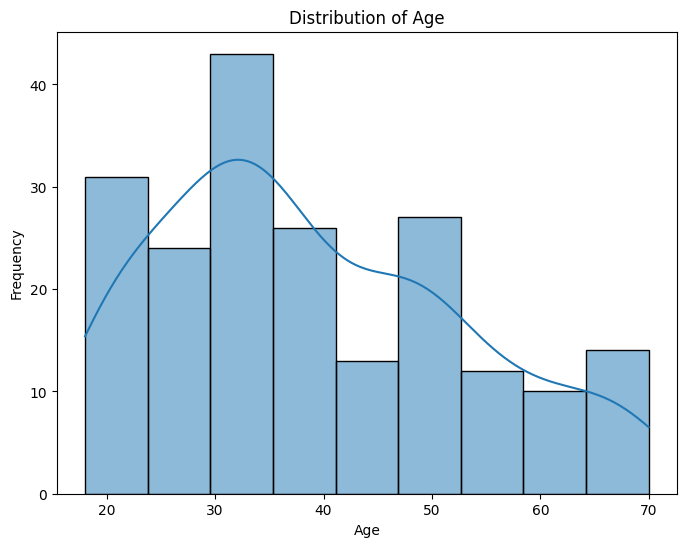

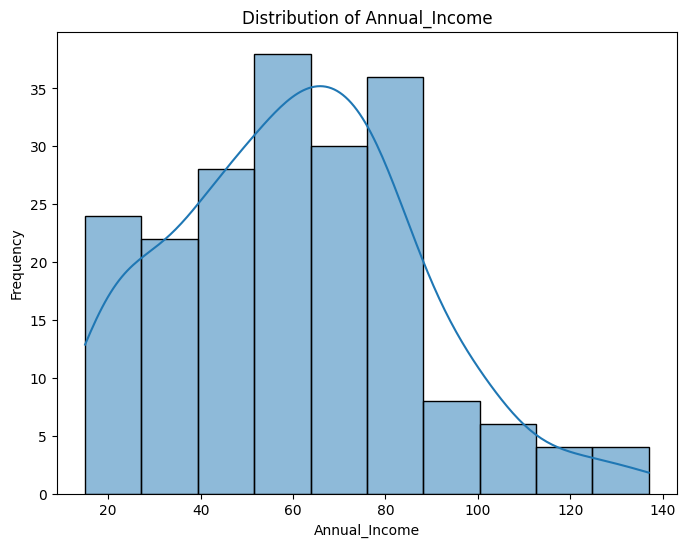

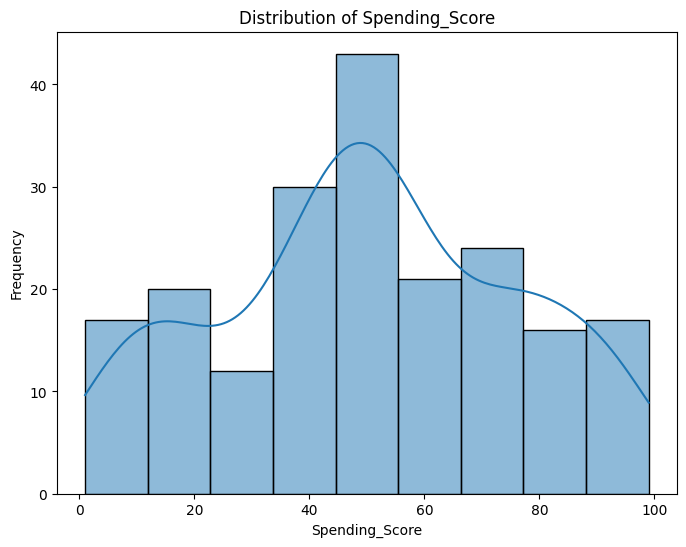

In [10]:
hist_cols = ['Age', 'Annual_Income', 'Spending_Score']
for col in hist_cols:
    plt.figure(figsize=(8, 6))
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.savefig(f'{col}_histogram.png')
    plt.show()

Purpose: understand the marginal distribution of each feature before clustering.


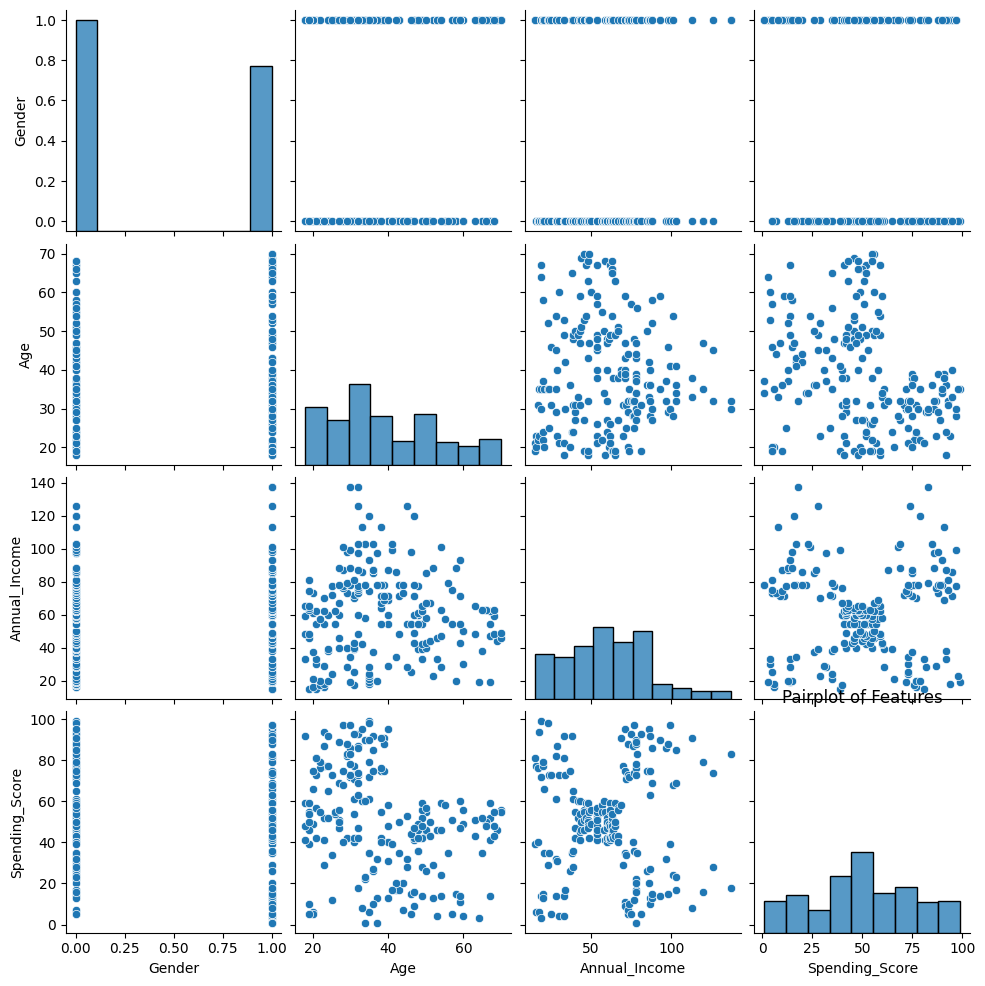

In [11]:
sns.pairplot(df, hue=None)
plt.title('Pairplot of Features')
plt.savefig('pairplot.png')
plt.show()

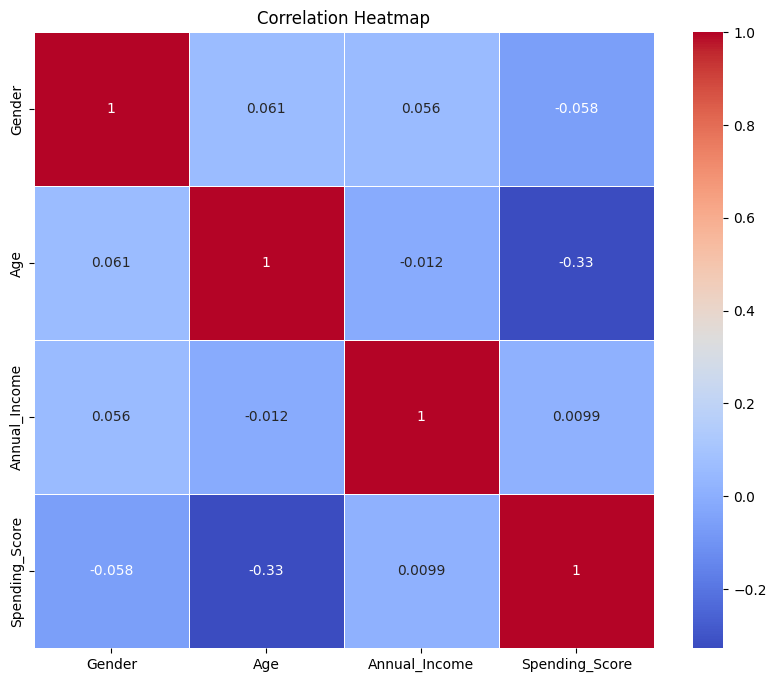

In [12]:
corr = df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.savefig('correlation_heatmap.png')
plt.show()

### EDA Summary

- Age ranges from 18 to 70 (mean 38.9). Annual income ranges from 15 to 137 k$ (mean 60.6), and spending score ranges from 1 to 99 (mean 50.2). The three features sit on different scales, which is why scaling is needed.
- The income distribution is right-skewed: a few customers earn far above the mean, so these will sit at the edge of the clusters.
- Correlations between the three numeric features are weak (check the heatmap values). Age and Spending_Score show the strongest, a mild negative one, so no pair of features is redundant.
- The pairplot shows clearly separated groups of points only in the Annual_Income vs Spending_Score panel, where five compact blobs are visible. The panels involving Age show no clear grouping.
- Annual_Income vs Spending_Score is therefore the best pair for clustering: it is the only pair with visible structure, and both features measure customer value, which makes the groups easy to name.

# Task 2: Feature Scaling & Feature Selection

In [13]:
df_scaled = df.copy()
scale_columns = ['Age', 'Annual_Income', 'Spending_Score']

scaler = StandardScaler()
df_scaled[scale_columns] = scaler.fit_transform(df[scale_columns])

In [14]:
df_scaled.head()

,Gender,Age,Annual_Income,Spending_Score
0,1,-1.424569,-1.738999,-0.434801
1,1,-1.281035,-1.738999,1.195704
2,0,-1.352802,-1.700830,-1.715913
3,0,-1.137502,-1.700830,1.040418
4,0,-0.563369,-1.662660,-0.395980


In [15]:
df_2f = df_scaled[['Annual_Income','Spending_Score']]

### Feature selection and why scaling is needed

`df_2f` uses Annual_Income and Spending_Score only. This pair showed the clearest structure in the EDA and allows a direct 2D scatter plot without PCA. Using all four features is valid but harder to visualise.

K-Means, Hierarchical (Ward) and DBSCAN all rely on Euclidean distance. Without scaling, Annual_Income (range 15–137) would dominate Spending_Score (range 1–99) and Age in every distance calculation, so clusters would reflect income alone. StandardScaler gives each feature mean 0 and standard deviation 1, so every feature contributes equally. Gender is binary and is left unscaled.

# Task 3: K-Means Clustering

In [16]:
inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_2f)
    inertia.append(kmeans.inertia_)

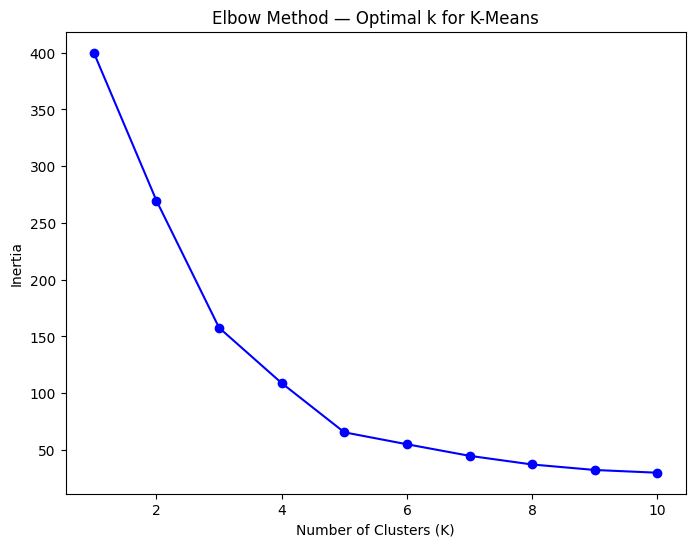

In [17]:
plt.figure(figsize=(8, 6))
plt.plot(range(1, 11), inertia, marker='o', linestyle='-', color='b')
plt.title('Elbow Method — Optimal k for K-Means')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.savefig('elbow_method.png')
plt.show()

### Elbow Method

Inertia is the sum of squared distances between each point and its assigned cluster centre. It always falls as k increases, because more centres are closer to the points. The elbow is the point after which adding another cluster reduces inertia only slightly. In this plot the curve bends at k = 5 and flattens afterwards, which suggests 5 clusters.

In [18]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_2f)
    labels = kmeans.labels_
    silhouette_avg = silhouette_score(df_2f, labels)
    silhouette_scores.append(silhouette_avg)
    print(f"For k={k}, Silhouette Score: {silhouette_avg}")

For k=2, Silhouette Score: 0.3212707813918878
For k=3, Silhouette Score: 0.46658474419000145
For k=4, Silhouette Score: 0.4939069237513199
For k=5, Silhouette Score: 0.5546571631111091
For k=6, Silhouette Score: 0.5398800926790663
For k=7, Silhouette Score: 0.5281492781108291
For k=8, Silhouette Score: 0.4552147906587443
For k=9, Silhouette Score: 0.4570853966942764
For k=10, Silhouette Score: 0.4431713026508046


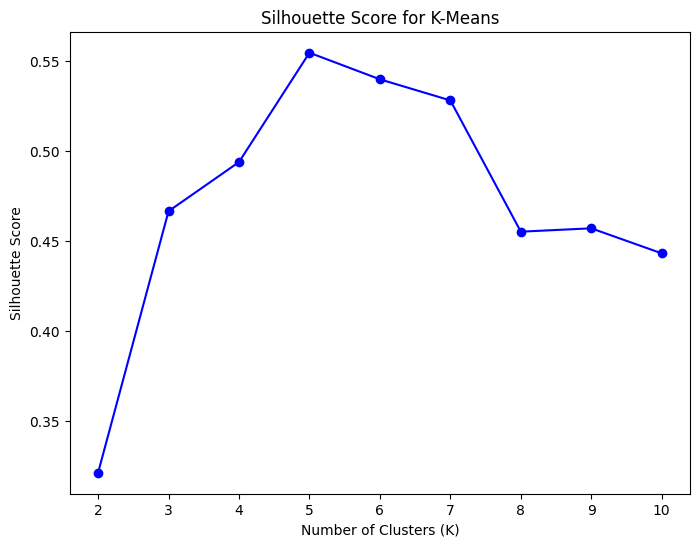

In [19]:
plt.figure(figsize=(8, 6))
plt.plot(range(2, 11), silhouette_scores, marker='o', linestyle='-', color='b')
plt.title('Silhouette Score for K-Means')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.savefig('silhouette_score.png')

### Silhouette Score and Comparison with the Elbow

The silhouette score is highest at k = 5 (0.5547), ahead of k = 6 (0.5399) and k = 4 (0.4939). It measures how close each point is to its own cluster compared with the nearest other cluster, so the highest value is the data-driven optimum. The Elbow and Silhouette methods agree on k = 5, so there is no discrepancy to explain. The Elbow method is a visual judgement, while the Silhouette score gives a number, which is why both are checked.

In [20]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df_scaled['KMeans_Cluster'] = kmeans.fit_predict(df_2f)

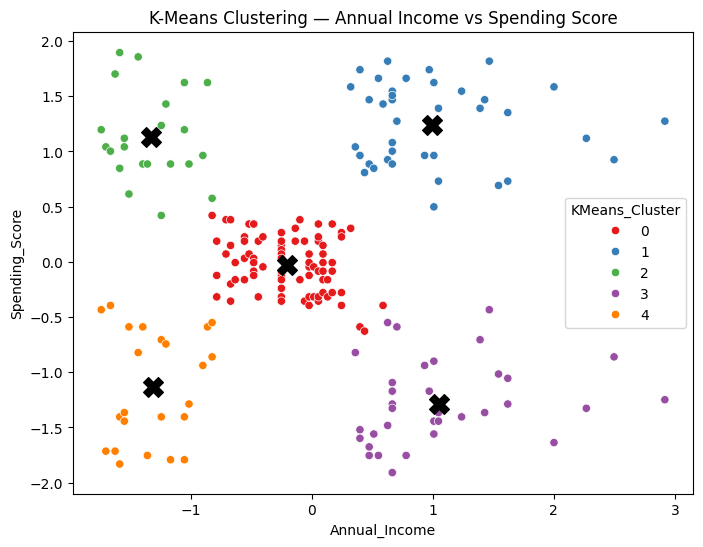

In [21]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=df_scaled['Annual_Income'],
    y=df_scaled['Spending_Score'],
    hue=df_scaled['KMeans_Cluster'],
    palette='Set1')
plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1], c='black', marker='X', s=200)
plt.title('K-Means Clustering — Annual Income vs Spending Score')
plt.show()

In [22]:
df_scaled.groupby('KMeans_Cluster')[['Age','Annual_Income','Spending_Score']].mean()

,Age,Annual_Income,Spending_Score
KMeans_Cluster,,,
0,0.277454,-0.200913,-0.026456
1,-0.441917,0.991583,1.239503
2,-0.974396,-1.329545,1.132178
3,0.162500,1.055003,-1.284439
4,0.456967,-1.307519,-1.136965


# Task 4: Agglomerative Hierarchical Clustering


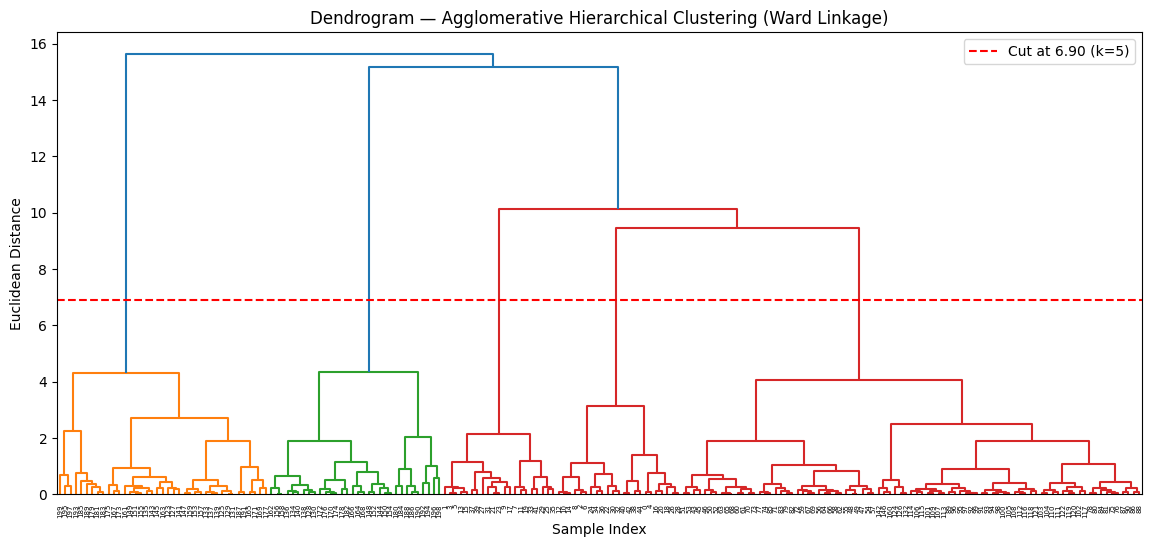

In [23]:
z = linkage(df_2f, method='ward')

plt.figure(figsize=(14, 6))
dendrogram(z)
plt.title('Dendrogram — Agglomerative Hierarchical Clustering (Ward Linkage)')
plt.xlabel('Sample Index')
plt.ylabel('Euclidean Distance')
cut = (z[-5, 2] + z[-4, 2]) / 2
plt.axhline(y=cut, color='r', linestyle='--', label=f'Cut at {cut:.2f} (k=5)')
plt.legend()
plt.savefig('dendrogram.png')
plt.show()

### Reading the Dendrogram

Ward linkage merges, at each step, the two clusters whose merge increases the total within-cluster variance the least. In the dendrogram, the vertical axis is the distance (variance increase) at which two branches join. A very tall vertical line means two quite different clusters were forced together, so the best cut is a horizontal line through the longest vertical stretch with no merges. This cut crosses five branches, which gives k = 5 and matches the K-Means choice.

In [24]:
agglomerative_clustering = AgglomerativeClustering(n_clusters=5, linkage='ward')
df_scaled['Hier_Cluster'] = agglomerative_clustering.fit_predict(df_2f)

In [25]:
df_scaled.head()

,Gender,Age,Annual_Income,Spending_Score,KMeans_Cluster,Hier_Cluster
0,1,-1.424569,-1.738999,-0.434801,4,4
1,1,-1.281035,-1.738999,1.195704,2,3
2,0,-1.352802,-1.700830,-1.715913,4,4
3,0,-1.137502,-1.700830,1.040418,2,3
4,0,-0.563369,-1.662660,-0.395980,4,4


In [26]:
df_scaled['Hier_Cluster'].value_counts()

,count
Hier_Cluster,
2,85
1,39
0,32
4,23
3,21


/tmp/ipykernel_1849/3371604848.py:1: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(x=df_scaled['Annual_Income'], y=df_scaled['Spending_Score'], c=df_scaled['Hier_Cluster'], palette='Set2')


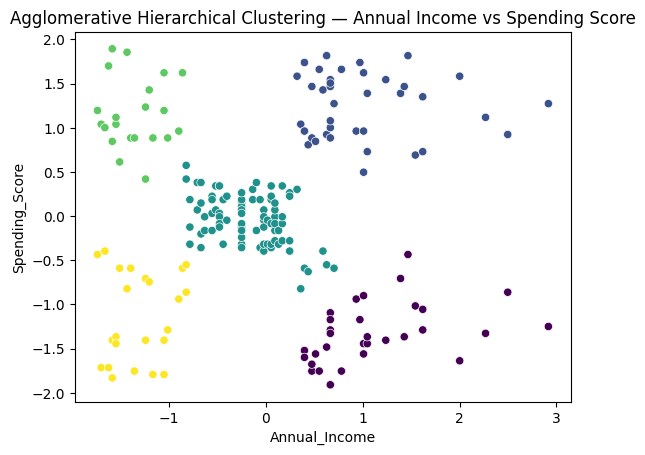

In [27]:
sns.scatterplot(x=df_scaled['Annual_Income'], y=df_scaled['Spending_Score'], c=df_scaled['Hier_Cluster'], palette='Set2')
plt.title('Agglomerative Hierarchical Clustering — Annual Income vs Spending Score')
plt.show()

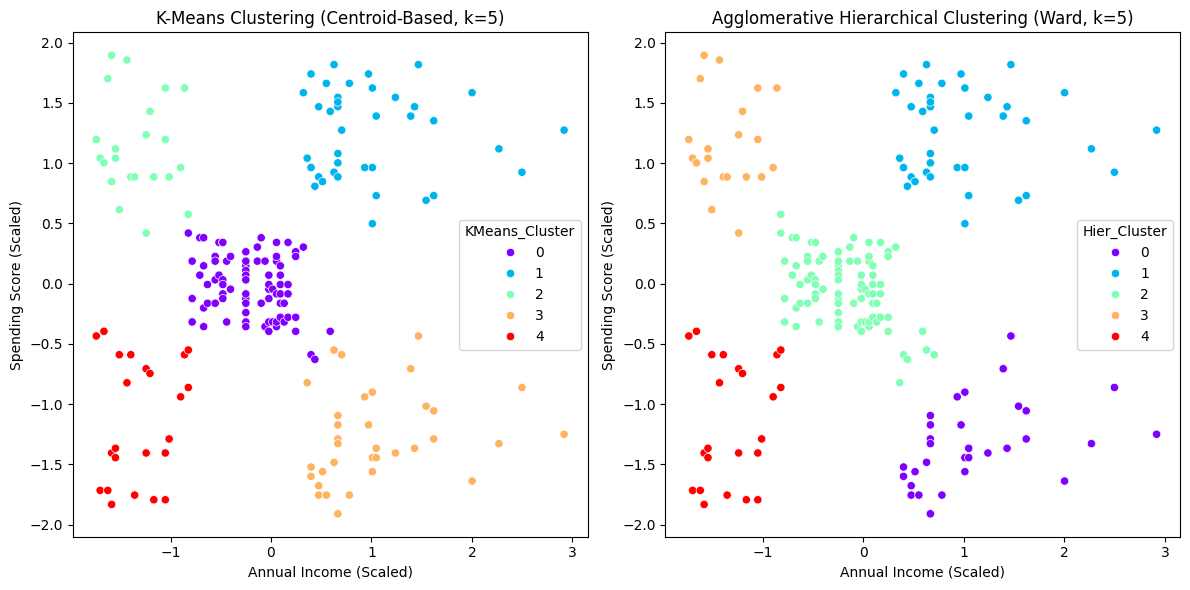

In [28]:
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
sns.scatterplot(
    x=df_scaled['Annual_Income'],
    y=df_scaled['Spending_Score'],
    hue=df_scaled['KMeans_Cluster'],
    palette='rainbow'
)
plt.title('K-Means Clustering (Centroid-Based, k=5)')
plt.xlabel('Annual Income (Scaled)')
plt.ylabel('Spending Score (Scaled)')

plt.subplot(1, 2, 2)
sns.scatterplot(
    x=df_scaled['Annual_Income'],
    y=df_scaled['Spending_Score'],
    hue=df_scaled['Hier_Cluster'],
    palette='rainbow'
)
plt.title('Agglomerative Hierarchical Clustering (Ward, k=5)')
plt.xlabel('Annual Income (Scaled)')
plt.ylabel('Spending Score (Scaled)')

plt.tight_layout()
plt.show()

### Profile Comparison

The Hierarchical profiles match the K-Means profiles cluster by cluster. Two groups are identical (income about +0.99, spend about +1.24; and income about -1.31, spend about -1.14, in scaled units). The other three differ only slightly (for example, the high-income low-spend group has spend -1.34 against -1.28). The segment definitions are therefore consistent, which gives confidence that the five segments are real structure and not an artefact of one algorithm.

In [29]:
df_scaled.groupby('Hier_Cluster')[['Age','Annual_Income','Spending_Score']].mean()

,Age,Annual_Income,Spending_Score
Hier_Cluster,,,
0,0.154298,1.101045,-1.343469
1,-0.441917,0.991583,1.239503
2,0.260682,-0.181237,-0.041562
3,-0.970046,-1.353670,1.158731
4,0.456967,-1.307519,-1.136965


# Task 5: DBSCAN Clustering

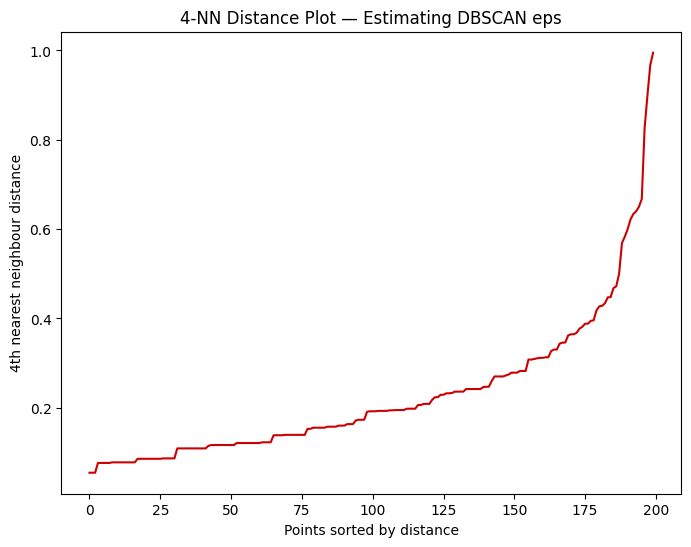

In [30]:
from sklearn.neighbors import NearestNeighbors

distances, _ = NearestNeighbors(n_neighbors=4).fit(df_2f).kneighbors(df_2f)
k_dist = np.sort(distances[:, -1])

plt.figure(figsize=(8, 6))
plt.plot(k_dist, color='#CC0000')
plt.title('4-NN Distance Plot — Estimating DBSCAN eps')
plt.xlabel('Points sorted by distance')
plt.ylabel('4th nearest neighbour distance')
plt.show()

In [31]:
rows = []
for eps in [0.2, 0.3, 0.4, 0.5, 0.6]:
    for ms in [3, 4, 5, 6]:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(df_2f)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = (labels == -1).sum()
        sil = silhouette_score(df_2f[labels != -1], labels[labels != -1]) if n_clusters >= 2 else np.nan
        rows.append([eps, ms, n_clusters, n_noise, sil])

grid = pd.DataFrame(rows, columns=['eps', 'min_samples', 'n_clusters', 'n_noise', 'silhouette'])
grid

,eps,min_samples,n_clusters,n_noise,silhouette
0,0.2,3,13,44,0.469713
1,0.2,4,5,73,0.617282
2,0.2,5,7,77,0.585613
3,0.2,6,4,95,0.613836
4,0.3,3,9,14,0.472040
5,0.3,4,8,23,0.519746
6,0.3,5,7,35,0.524328
7,0.3,6,6,48,0.530244
8,0.4,3,4,10,0.395381
9,0.4,4,3,14,0.457570


In [32]:
dbscan = DBSCAN(eps=0.4, min_samples=5)
df_scaled['DBSCAN_Cluster'] = dbscan.fit_predict(df_2f)
df_scaled['DBSCAN_Cluster'].value_counts()

,count
DBSCAN_Cluster,
0,115
2,32
3,27
-1,15
1,11


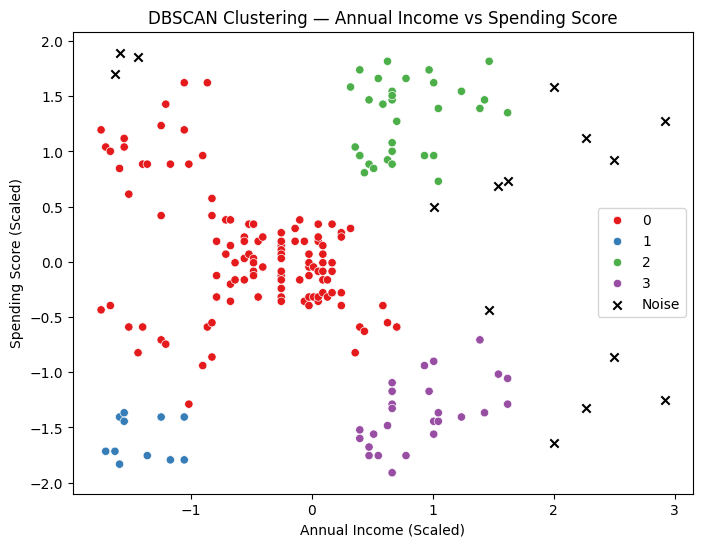

In [33]:
plt.figure(figsize=(8, 6))
ok = df_scaled[df_scaled['DBSCAN_Cluster'] != -1]
noise = df_scaled[df_scaled['DBSCAN_Cluster'] == -1]

sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='DBSCAN_Cluster', data=ok, palette='Set1')
plt.scatter(noise['Annual_Income'], noise['Spending_Score'], c='black', marker='x', label='Noise')

plt.title('DBSCAN Clustering — Annual Income vs Spending Score')
plt.xlabel('Annual Income (Scaled)')
plt.ylabel('Spending Score (Scaled)')
plt.legend()
plt.savefig('dbscan_clustering.png')
plt.show()

### What eps and min_samples control

- **eps** is the neighbourhood radius. If it is too small, real segments break apart and become noise. If it is too large, separate segments merge. The grid shows both effects: at eps = 0.2 there are 73–95 noise points, and at eps = 0.5 and above everything merges into 1–2 clusters.
- **min_samples** is the number of points (including the point itself) needed inside eps for a point to be a core point. Higher values require denser regions and produce more noise.
- **Noise points (-1)** are not core points and are not within eps of a core point. They are too far from any dense region to belong to a cluster. They are the 15 black x markers in the plot.

# Task 6: Algorithm Comparison & Business Insights


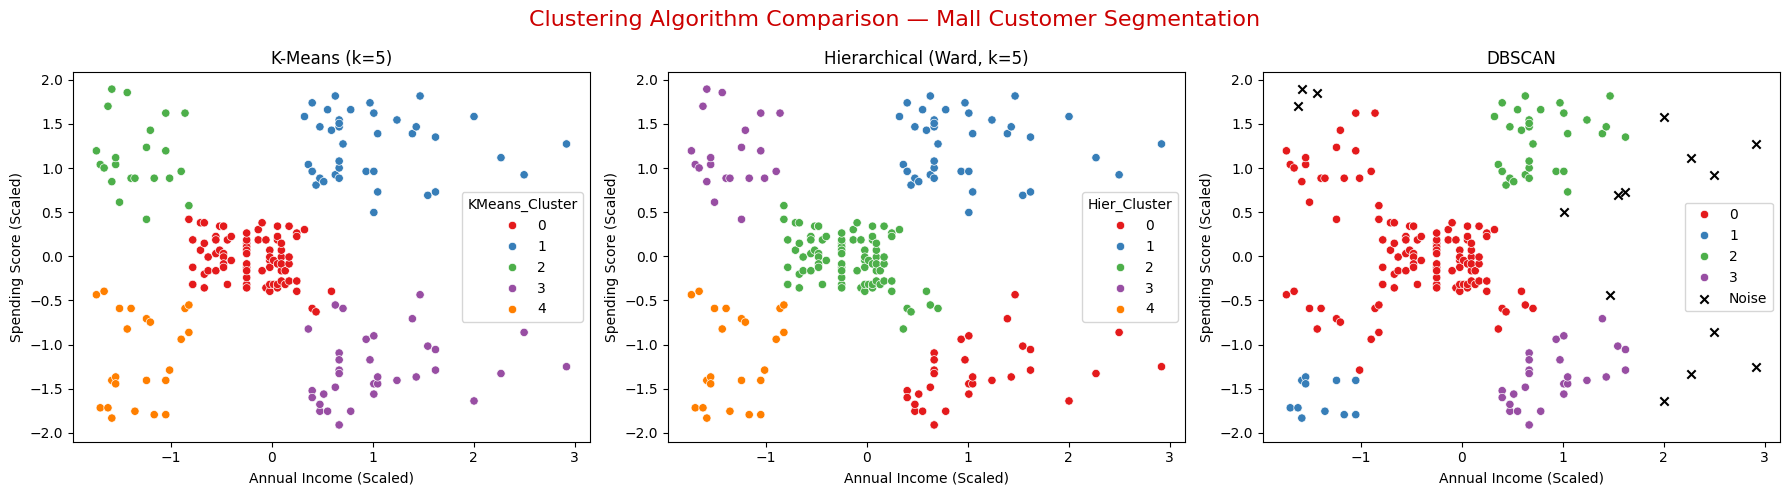

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='KMeans_Cluster',
                data=df_scaled, palette='Set1', ax=axes[0])
axes[0].set_title('K-Means (k=5)')

sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='Hier_Cluster',
                data=df_scaled, palette='Set1', ax=axes[1])
axes[1].set_title('Hierarchical (Ward, k=5)')

db_ok = df_scaled[df_scaled['DBSCAN_Cluster'] != -1]
db_noise = df_scaled[df_scaled['DBSCAN_Cluster'] == -1]
sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='DBSCAN_Cluster',
                data=db_ok, palette='Set1', ax=axes[2])
axes[2].scatter(db_noise['Annual_Income'], db_noise['Spending_Score'],
                c='black', marker='x', label='Noise')
axes[2].set_title('DBSCAN')
axes[2].legend()

for ax in axes:
    ax.set_xlabel('Annual Income (Scaled)')
    ax.set_ylabel('Spending Score (Scaled)')

fig.suptitle('Clustering Algorithm Comparison — Mall Customer Segmentation',
             fontsize=16, color='#CC0000')
plt.tight_layout()
plt.savefig('three_panel_comparison.png', bbox_inches='tight')
plt.show()

In [35]:
def evaluate(name, labels):
    mask = labels != -1
    X, y = df_2f[mask], labels[mask]
    return {
        'Algorithm': name,
        'n_clusters': len(set(y)),
        'Silhouette': round(silhouette_score(X, y), 4)
    }

metrics = pd.DataFrame([
    evaluate('K-Means', df_scaled['KMeans_Cluster'].values),
    evaluate('Hierarchical', df_scaled['Hier_Cluster'].values),
    evaluate('DBSCAN (noise excluded)', df_scaled['DBSCAN_Cluster'].values),
])
metrics

,Algorithm,n_clusters,Silhouette
0,K-Means,5,0.5547
1,Hierarchical,5,0.5538
2,DBSCAN (noise excluded),4,0.4781


In [36]:
df['KMeans_Cluster'] = df_scaled['KMeans_Cluster']

profile = df.groupby('KMeans_Cluster')[['Age', 'Annual_Income', 'Spending_Score']].mean().round(1)
profile['Customers'] = df['KMeans_Cluster'].value_counts().sort_index()

def label(v, low, high):
    return 'Low' if v < low else 'High' if v > high else 'Mid'

profile['Segment'] = [
    f"{label(r.Annual_Income, 40, 70)} Income, {label(r.Spending_Score, 40, 60)} Spend"
    for r in profile.itertuples()
]
profile

,Age,Annual_Income,Spending_Score,Customers,Segment
KMeans_Cluster,,,,,
0,42.7,55.3,49.5,81,"Mid Income, Mid Spend"
1,32.7,86.5,82.1,39,"High Income, High Spend"
2,25.3,25.7,79.4,22,"Low Income, High Spend"
3,41.1,88.2,17.1,35,"High Income, Low Spend"
4,45.2,26.3,20.9,23,"Low Income, Low Spend"


# Business Insights for Mall Management



## (a) Customer Segments Identified by K-Means (k = 5)

K-Means is used for this report because its centroids map directly to named, explainable customer groups. Profiles below are averages of the original (unscaled) values.

| Segment | Customers | Share | Avg Age | Avg Annual Income (k$) | Avg Spending Score |
|---|---|---|---|---|---|
| Mid Income, Mid Spend | 81 | 40.5% | 42.7 | 55.3 | 49.5 |
| High Income, High Spend | 39 | 19.5% | 32.7 | 86.5 | 82.1 |
| Low Income, High Spend | 22 | 11.0% | 25.3 | 25.7 | 79.4 |
| High Income, Low Spend | 35 | 17.5% | 41.1 | 88.2 | 17.1 |
| Low Income, Low Spend | 23 | 11.5% | 45.2 | 26.3 | 20.9 |

**1. Mid Income, Mid Spend (the core majority).** At 81 customers, this is the largest group and about 40% of all customers. They earn and spend at average levels and are middle-aged (around 43). Because they sit close to every other segment, they are the group most likely to move up or down depending on how the mall treats them.

**2. High Income, High Spend (the premium customers).** 39 customers, averaging 86.5 k$ income and a spending score of 82. They are younger (around 33), financially strong and actively shopping. This is the most valuable segment and the one to protect.

**3. Low Income, High Spend (young enthusiasts).** 22 customers and the youngest group (around 25). Their income is low (25.7 k$) but their spending score is almost as high as the premium segment (79.4). They spend a large share of their income in the mall, so they respond strongly to deals.

**4. High Income, Low Spend (the untapped opportunity).** 35 customers earning 88.2 k$, the highest income of any segment, yet with a spending score of only 17.1. They have the money but are not spending it here, which suggests the current offering does not appeal to them or they shop elsewhere.

**5. Low Income, Low Spend (the budget-conscious).** 23 customers, the oldest group (around 45), with low income (26.3 k$) and low spending (20.9). They visit and spend little, and the mall has limited room to grow revenue from them.

## (b) Recommended Marketing Action per Segment

| Segment | Targeted Action | Rationale |
|---|---|---|
| High Income, High Spend | **VIP loyalty programme**: early access to sales, exclusive events, personal shopping offers. | Highest value; retention matters more than acquisition. Losing even a few of these 39 customers costs more than any other segment. |
| High Income, Low Spend | **Premium brand and lifestyle campaigns**: new luxury and dining brands, personalised invitations, curated events. | The income is there (88.2 k$); the gap is in engagement. Even a modest rise in spending here gives the biggest revenue gain. |
| Low Income, High Spend | **Budget promotions**: discount days, instalment offers, student and youth deals, and a points scheme. | They already spend heavily relative to income, so the goal is to keep them loyal with value, not to push for more spending. |
| Mid Income, Mid Spend | **General rewards scheme and seasonal offers**: a tiered programme that rewards spending upgrades. | The largest group; a small uplift per customer adds up across 81 people. A tier structure encourages them to move toward the High Spend group. |
| Low Income, Low Spend | **Low-cost, high-reach promotions**: coupons, food-court and entertainment deals. Avoid expensive targeted campaigns. | Revenue potential is low, so campaign cost must stay low. The aim is to maintain footfall, not to invest heavily. |

## (c) Recommended Algorithm for Deployment

**Recommendation: K-Means.**

- **Interpretability.** Each cluster has a centroid that translates directly into a business segment with a name, a size and an average profile. The marketing team can act on this without technical knowledge.
- **New customers.** A new customer can be assigned to a segment immediately by finding the nearest centroid. Hierarchical clustering and DBSCAN have no equivalent simple prediction step.
- **Stable results on this data.** The Income vs Spending Score space forms compact, well-separated groups, which is the situation K-Means handles best. The three algorithms broadly agree on the main segments, so the simplest method is sufficient.

**When the alternatives are better:**
- **DBSCAN** is the better choice when cluster shapes are unknown or when outlier customers must be flagged explicitly rather than forced into a segment.
- **Hierarchical clustering** is the better choice when management needs a dendrogram to see how segments merge, for example to decide between 3 broad groups and 5 detailed groups in a presentation.

